Objective: To understand how regression is applied to a real-world problem by building a House Price Prediction model using Linear Regression.

House Price prediction is a regression problem where we predict the price of a house based on features such as: Area, Number of bedrooms, Number of bathrooms, Location-related factors (simplied here)

In this lab, we will learn: how to load a dataset, explore and preprocess data, train a regression model, evaluate performance, and make predictions.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [4]:
#load dataset
df = pd.read_csv('house_price_prediction.csv')
df

,avg_income,avg_area_house_age,avg_area_num_rooms,avg_bedrooms,avg_population,price,address
0,79545.45857,5.682861,7.009188,4.09,23086.80050,1.059034e+06,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.64245,6.002900,6.730821,3.09,40173.07217,1.505891e+06,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.06718,5.865890,8.512727,5.13,36882.15940,1.058988e+06,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.24005,7.188236,5.586729,3.26,34310.24283,1.260617e+06,USS Barnett\nFPO AP 44820
4,59982.19723,5.040555,7.839388,4.23,26354.10947,6.309435e+05,USNS Raymond\nFPO AE 09386
...,...,...,...,...,...,...,...
5007,60567.94414,7.830362,6.137356,3.46,22837.36103,1.060194e+06,USNS Williams\nFPO AP 30153-7653
5008,NaN,6.999135,6.576763,4.02,25616.11549,1.482618e+06,"PSC 9258, Box 8489\nAPO AA 42991-3352"
5009,NaN,7.250591,4.805081,2.13,33266.14549,1.030730e+06,"4215 Tracy Garden Suite 076\nJoshualand, VA 01..."
5010,68001.33124,5.534388,7.130144,5.44,42625.62016,1.198657e+06,USS Wallace\nFPO AE 73316


In [5]:
#understand the data
df.info() #gives the number of rows and columns, datatype

In [6]:
df.describe() #gives us the statistical data - mean, std, min, skewed or not skewed

,avg_income,avg_area_house_age,avg_area_num_rooms,avg_bedrooms,avg_population,price
count,5009.000000,5010.000000,5011.000000,5012.000000,5009.000000,5.012000e+03
mean,68577.804938,5.977508,6.987906,3.982095,36155.832559,1.231947e+06
std,10661.033166,0.991472,1.006453,1.233945,9928.823462,3.529525e+05
min,17796.631190,2.644304,3.236194,2.000000,172.610686,1.593866e+04
25%,61482.244790,5.322274,6.298437,3.140000,29403.512060,9.981375e+05
50%,68814.925610,5.969828,7.003188,4.050000,36183.287800,1.232983e+06
75%,75780.621120,6.652302,7.667048,4.490000,42841.741620,1.471756e+06
max,107701.748400,9.519088,10.759588,6.500000,69621.713380,2.469066e+06


In [7]:
#check for missing values
df.isnull().sum()

avg_income            3
avg_area_house_age    2
avg_area_num_rooms    1
avg_bedrooms          0
avg_population        3
price                 0
address               1
dtype: int64

In [10]:
#drop rows containing null values
df = df.dropna()

In [12]:
#feature selection
X = df.drop(['price', 'address'], axis = 1) #remove 'price' because it is the target and 'address' because it is text data which regression does not understand non-numerical values.
y = df['price'] #y contains the value we want to predict which is 'price'

Train-test split data: 80% training data (is where the model learns from), 20% testing data (is used to test the model), random_state ensure reproducibility

In [14]:
#Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state=42
)

In [15]:
#training the model using the Linear Regression algorithm
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](5,)","[ 21.44,165337.43,122385.8 , -87. , 15.11]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](5,)","['avg_income','avg_area_house_age','avg_area_num_rooms','avg_bedrooms', 'avg_population']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-2.629e+06
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(5)


In [17]:
#model coefficients
coeff_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})
print(coeff_df)
# shows how much each feature contributes to price
# higher coefficient → stronger impact

              Feature    Coefficient
0          avg_income      21.437583
1  avg_area_house_age  165337.433096
2  avg_area_num_rooms  122385.801481
3        avg_bedrooms     -87.003861
4      avg_population      15.107113


In [19]:
#use the training model to make predictions
y_pred = model.predict(X_test)

Model Evaluation:
MAE → Average Absolute Error,
MSE → Squared error penalty,
RMSE → interpretable error, 
R^2 Score → how well model explains variance (closer to 1 is better)

In [21]:
#model evaluation
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

MAE: 83034.97988314532
MSE: 10631960441.626982
RMSE: 103111.39821390738
R2 Score: 0.9172709716777082


Text(0.5, 1.0, 'Actual vs Predicted House Prices')

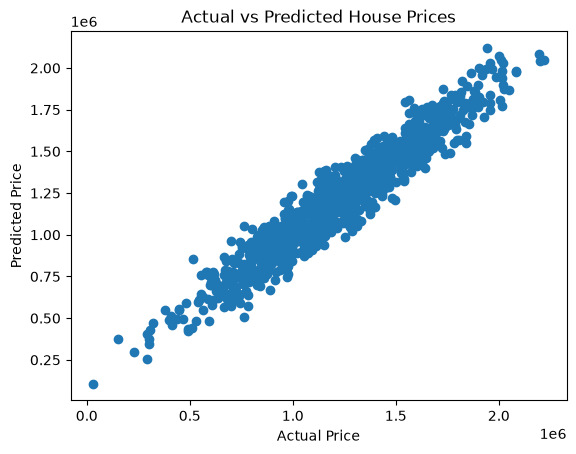

In [23]:
#Visualization - Actual VS Predicted Prices
plt.scatter(y_test, y_pred)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House Prices") #if points are close to the diagonal line → means good predictions

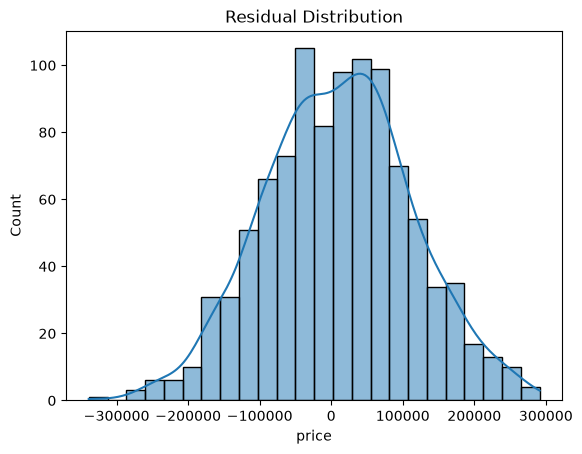

In [24]:
#Residual Analysis
residuals = y_test - y_pred

sns.histplot(residuals, kde="True") #Residuals should be normally distributed (centered around 0).
plt.title("Residual Distribution")
plt.show() #residuals indicates whether it is a good linear regression fit.

In [26]:
#Predict for a New House Example:
new_house = [[75000, 6, 7, 4, 30000]]
predicted_price = model.predict(new_house)

print("Predicted House Price:", predicted_price[0])

Predicted House Price: 1279993.2087541735


C:\Users\joann\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


The trained model predicts house prices and demonstrates real-world usage.